### LOAD DATASET

In [3]:
import pandas as pd

df = pd.read_excel("NF-UNSW-NB15.xlsx")

In [4]:
import os

file_size = os.path.getsize("NF-UNSW-NB15.xlsx") / (1024**2)

print(f"Dataset size: {file_size:.2f} MB")

Dataset size: 70.36 MB


### inspect the Excel file safely

In [5]:

from openpyxl import load_workbook

wb = load_workbook("NF-UNSW-NB15.xlsx", read_only=True)

print("Sheets:", wb.sheetnames)

for sheet in wb.worksheets:
    print(sheet.title, "→", sheet.max_row, "rows,", sheet.max_column, "columns")

Sheets: ['NF-UNSW-NB15']
NF-UNSW-NB15 → 1048576 rows, 14 columns


### inspect just the first few rows

In [6]:


from openpyxl import load_workbook

wb = load_workbook("NF-UNSW-NB15.xlsx", read_only=True)
ws = wb["NF-UNSW-NB15"]

for row in ws.iter_rows(min_row=1, max_row=6, values_only=True):
    print(row)

('IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack')
('149.171.126.0', 62073, '59.166.0.5', 56082, 6, 0, 9672, 416, 11, 8, 25, 15, 0, 'Benign')
('149.171.126.2', 32284, '59.166.0.5', 1526, 6, 0, 1776, 104, 6, 2, 25, 0, 0, 'Benign')
('149.171.126.0', 21, '59.166.0.1', 21971, 6, 1, 1842, 1236, 26, 22, 25, 1111, 0, 'Benign')
('59.166.0.1', 23800, '149.171.126.0', 46893, 6, 0, 528, 8824, 10, 12, 27, 124, 0, 'Benign')
('59.166.0.5', 63062, '149.171.126.2', 21, 6, 1, 1786, 2340, 32, 34, 25, 1459, 0, 'Benign')


### Create a 200,000-row sample

In [7]:
import pandas as pd

df = pd.read_excel(
    "NF-UNSW-NB15.xlsx",
    nrows=200000
)

print("Shape:", df.shape)

Shape: (200000, 14)



### Inspect the dataset

#### 1. Column names
#### 2. Data types + missing values
#### 3. Attack distribution

In [8]:

print(df.columns.tolist())

['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']


In [9]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   IPV4_SRC_ADDR               200000 non-null  object 
 1   L4_SRC_PORT                 200000 non-null  int64  
 2   IPV4_DST_ADDR               200000 non-null  object 
 3   L4_DST_PORT                 200000 non-null  int64  
 4   PROTOCOL                    200000 non-null  int64  
 5   L7_PROTO                    200000 non-null  float64
 6   IN_BYTES                    200000 non-null  int64  
 7   OUT_BYTES                   200000 non-null  int64  
 8   IN_PKTS                     200000 non-null  int64  
 9   OUT_PKTS                    200000 non-null  int64  
 10  TCP_FLAGS                   200000 non-null  int64  
 11  FLOW_DURATION_MILLISECONDS  200000 non-null  int64  
 12  Label                       200000 non-null  int64  
 13  Attack        

In [10]:
print(df["Attack"].value_counts())

Attack
Benign            186734
Exploits            4765
Fuzzers             3248
Reconnaissance      2332
Generic             1009
DoS                  942
Backdoor             349
Analysis             334
Shellcode            258
Worms                 29
Name: count, dtype: int64


### Let's check the amount of bengin and attack

In [11]:
print(df["Label"].value_counts())

Label
0    186734
1     13266
Name: count, dtype: int64


#### in our 200,000-row sample:

#### 93.37% Benign
#### 6.63% Attack

### create X and y

In [12]:
features = [
    'L4_SRC_PORT',
    'L4_DST_PORT',
    'PROTOCOL',
    'L7_PROTO',
    'IN_BYTES',
    'OUT_BYTES',
    'IN_PKTS',
    'OUT_PKTS',
    'TCP_FLAGS',
    'FLOW_DURATION_MILLISECONDS'
]

X = df[features]
y = df['Label']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200000, 10)
y shape: (200000,)




### Split the data

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (160000, 10)
X_test : (40000, 10)
y_train: (160000,)
y_test : (40000,)


### Scale the features

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (160000, 10)
X_test_scaled shape : (40000, 10)



### Random Forest

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [30]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
---------------------
Accuracy : 0.9839
Precision: 0.8369
Recall   : 0.9416
F1 Score : 0.8861

Confusion Matrix:
[[36860   487]
 [  155  2498]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     37347
           1       0.84      0.94      0.89      2653

    accuracy                           0.98     40000
   macro avg       0.92      0.96      0.94     40000
weighted avg       0.99      0.98      0.98     40000



In [32]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()

fpr_rf = fp / (fp + tn)
fnr_rf = fn / (fn + tp)

print(f"False Positive Rate (FPR): {fpr_rf:.4f}")
print(f"False Negative Rate (FNR): {fnr_rf:.4f}")

False Positive Rate (FPR): 0.0130
False Negative Rate (FNR): 0.0584


#### Model performance comparison 

In [34]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "ANN",
        "Random Forest"
    ],
    "Accuracy": [
        0.940275,
        0.9602,
        0.98395
    ],
    "Precision": [
        0.75,
        0.6293,
        0.836851
    ],
    "Recall": [
        0.15,
        0.9732,
        0.941576
    ],
    "F1 Score": [
        0.25,
        0.7644,
        0.88613
    ],
    "FPR": [
        0.0035,
        0.0407,
        0.01304
    ],
    "FNR": [
        0.8500,
        0.0268,
        0.058424
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,FPR,FNR
0,Logistic Regression,0.940275,0.750000,0.150000,0.25000,0.00350,0.850000
1,ANN,0.960200,0.629300,0.973200,0.76440,0.04070,0.026800
2,Random Forest,0.983950,0.836851,0.941576,0.88613,0.01304,0.058424


### Baseline 1 — Normal Logistic Regression

### High accuracy, terrible attack detection:

### 94% accuracy → 15% attack recall

In [16]:


from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training complete.")

Logistic Regression training complete.


In [17]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("Predictions completed.")

Predictions completed.


In [18]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.940275

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     37347
           1       0.75      0.15      0.25      2653

    accuracy                           0.94     40000
   macro avg       0.85      0.57      0.61     40000
weighted avg       0.93      0.94      0.92     40000



In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[37216   131]
 [ 2258   395]]


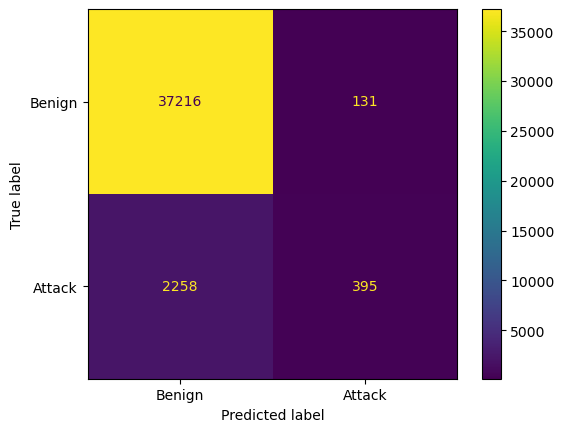

In [20]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
)

disp.plot()
plt.show()

### Baseline 2 — Balanced Logistic Regression

### Much better attack detection:

### 70% accuracy → 89% attack recall

### Imporoved Logistic Regression

In [21]:
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_test_scaled)

In [22]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_balanced))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))


              precision    recall  f1-score   support

           0       0.99      0.69      0.81     37347
           1       0.17      0.89      0.28      2653

    accuracy                           0.70     40000
   macro avg       0.58      0.79      0.55     40000
weighted avg       0.93      0.70      0.77     40000

Confusion Matrix:
[[25598 11749]
 [  280  2373]]




## Build the ANN



In [23]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [24]:
import sys

print(sys.version)
print(sys.executable)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
E:\ anaconda yeeee\python.exe


In [25]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [26]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(10,)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

ann_model.summary()

E:\ anaconda yeeee\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(
    zip(np.unique(y_train), class_weights)
)

print("Class weights:", class_weight_dict)

Class weights: {np.int64(0): np.float64(0.535521832555711), np.int64(1): np.float64(7.537925186092528)}


### Train the ANN

In [28]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8094 - loss: 0.4107 - val_accuracy: 0.9008 - val_loss: 0.2831
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8803 - loss: 0.2912 - val_accuracy: 0.8938 - val_loss: 0.2752
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8795 - loss: 0.2546 - val_accuracy: 0.8626 - val_loss: 0.2844
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8754 - loss: 0.2214 - val_accuracy: 0.8934 - val_loss: 0.2285
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8715 - loss: 0.2006 - val_accuracy: 0.9552 - val_loss: 0.1772
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8851 - loss: 0.1906 - val_accuracy: 0.9142 - val_loss: 0.2026
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9062 - loss: 0.1789 - val_accuracy: 0.9542 - val_loss: 0.1775
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9246 - loss: 0.1680 - val_accuracy: 0.

### Test the ANN

In [44]:
y_prob_ann = ann_model.predict(X_test_scaled)

y_pred_ann = (y_prob_ann >= 0.5).astype(int).ravel()

print("Predictions completed.")

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 782us/step
Predictions completed.


In [45]:
from sklearn.metrics import classification_report, confusion_matrix

print("ANN Classification Report:")
print(classification_report(y_test, y_pred_ann))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ann))

ANN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     37347
           1       0.62      0.99      0.76      2653

    accuracy                           0.96     40000
   macro avg       0.81      0.97      0.87     40000
weighted avg       0.97      0.96      0.96     40000

Confusion Matrix:
[[35775  1572]
 [   39  2614]]


### The important comparison

#### Our normal Logistic Regression had:

#### 94% accuracy but detected only 15% of attacks.

#### Our ANN has:

#### 96% accuracy and detects ~97% of attacks.

#### That's a major improvement.

### Plot ANN Learning Curves:-

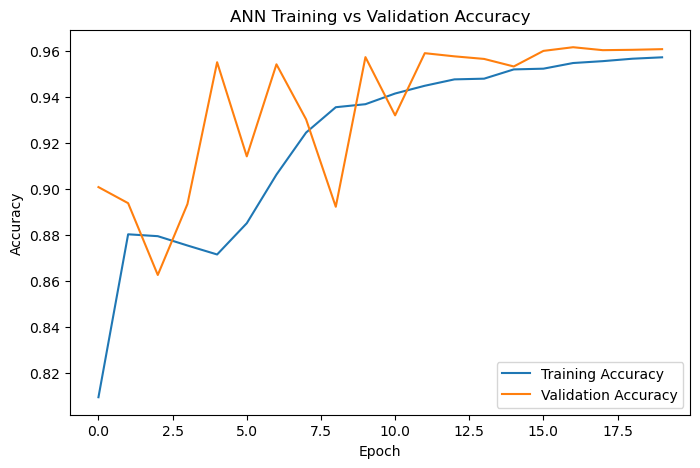

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('ANN Training vs Validation Accuracy')
plt.legend()
plt.show()

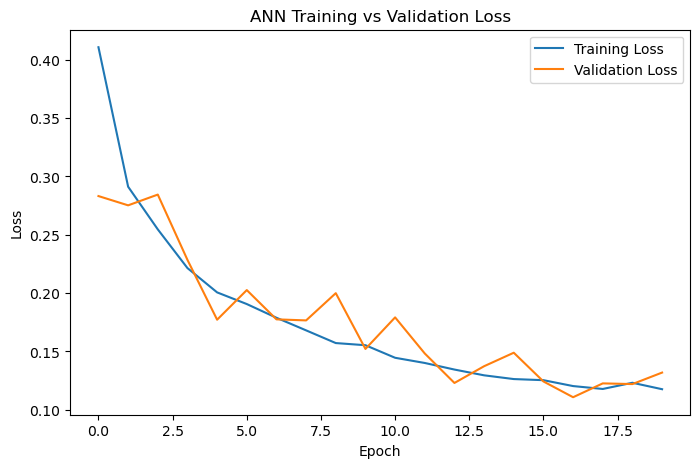

In [36]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ANN Training vs Validation Loss')
plt.legend()
plt.show()


### Calculating NIDS metrices

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_ann).ravel()

accuracy = accuracy_score(y_test, y_pred_ann)
precision = precision_score(y_test, y_pred_ann)
recall = recall_score(y_test, y_pred_ann)
f1 = f1_score(y_test, y_pred_ann)

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("FPR      :", fpr)
print("FNR      :", fnr)

Accuracy : 0.959725
Precision: 0.6244624940277114
Recall   : 0.9852996607614022
F1 Score : 0.7644392455037287
FPR      : 0.04209173427584545
FNR      : 0.014700339238597813


### Compare all three models

In [47]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "ANN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_ann)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_ann)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_ann)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_ann)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.940275,0.750951,0.148888,0.248506
1,Balanced Logistic Regression,0.699275,0.168036,0.894459,0.282921
2,ANN,0.959725,0.624462,0.985300,0.764439


### Attach the actual attack type to our test predictions

In [48]:
test_results = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": y_pred_ann
}, index=y_test.index)

test_results["Attack_Type"] = df.loc[
    y_test.index, "Attack"
]

test_results.head()

,Actual_Label,Predicted_Label,Attack_Type
17050,0,0,Benign
126030,0,0,Benign
176031,0,0,Benign
53215,1,1,Exploits
199861,0,0,Benign


### Check how many attacks of each type are in the test set


In [49]:
test_results[test_results["Actual_Label"] == 1]["Attack_Type"].value_counts()

Attack_Type
Exploits          924
Fuzzers           704
Reconnaissance    464
DoS               196
Generic           188
Analysis           62
Backdoor           59
Shellcode          49
Worms               7
Name: count, dtype: int64

### Now attack wise detection rate:-

In [50]:
attack_results = test_results[
    test_results["Actual_Label"] == 1
].copy()

attack_results["Correct"] = (
    attack_results["Actual_Label"] ==
    attack_results["Predicted_Label"]
)

attack_recall = (
    attack_results
    .groupby("Attack_Type")["Correct"]
    .agg(["sum", "count"])
)

attack_recall["Recall"] = (
    attack_recall["sum"] /
    attack_recall["count"]
)

attack_recall = attack_recall.sort_values(
    "Recall",
    ascending=False
)

attack_recall

,sum,count,Recall
Attack_Type,,,
Analysis,62,62,1.000000
Fuzzers,704,704,1.000000
Worms,7,7,1.000000
Shellcode,49,49,1.000000
Reconnaissance,464,464,1.000000
Backdoor,58,59,0.983051
Exploits,899,924,0.972944
DoS,190,196,0.969388
Generic,181,188,0.962766


### Threshold analysis

In [51]:
y_pred_ann = (y_prob_ann >= 0.5)

#### Test different thresholds:-

In [52]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

for threshold in thresholds:
    predictions = (y_prob_ann >= threshold).astype(int).ravel()

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    fpr = fp / (fp + tn)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"FPR:       {fpr:.4f}")


Threshold: 0.3
Precision: 0.4442
Recall:    0.9925
F1 Score:  0.6137
FPR:       0.0882

Threshold: 0.4
Precision: 0.5419
Recall:    0.9902
F1 Score:  0.7004
FPR:       0.0595

Threshold: 0.5
Precision: 0.6245
Recall:    0.9853
F1 Score:  0.7644
FPR:       0.0421

Threshold: 0.6
Precision: 0.6349
Recall:    0.9793
F1 Score:  0.7703
FPR:       0.0400

Threshold: 0.7
Precision: 0.6470
Recall:    0.9631
F1 Score:  0.7740
FPR:       0.0373


In [53]:
final_threshold = 0.70

y_pred_final = (y_prob_ann >= final_threshold).astype(int).ravel()

print("Final ANN Classification Report:")
print(classification_report(y_test, y_pred_final))

print("Final Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final ANN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     37347
           1       0.65      0.96      0.77      2653

    accuracy                           0.96     40000
   macro avg       0.82      0.96      0.88     40000
weighted avg       0.97      0.96      0.97     40000

Final Confusion Matrix:
[[35953  1394]
 [   98  2555]]


In [54]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_final
).ravel()

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)

final_fpr = fp / (fp + tn)
final_fnr = fn / (fn + tp)

print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1 Score :", final_f1)
print("FPR      :", final_fpr)
print("FNR      :", final_fnr)

Accuracy : 0.9627
Precision: 0.6469992403140036
Recall   : 0.9630606860158312
F1 Score : 0.7740078764010906
FPR      : 0.03732562187056524
FNR      : 0.036939313984168866


### Final Model Comparison

In [55]:
final_threshold = 0.70

y_pred_final = (y_prob_ann >= final_threshold).astype(int).ravel()

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_final
).ravel()

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)

final_fpr = fp / (fp + tn)
final_fnr = fn / (fn + tp)

print("Final ANN Results")
print("-----------------")
print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1 Score :", round(final_f1, 4))
print("FPR      :", round(final_fpr, 4))
print("FNR      :", round(final_fnr, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final ANN Results
-----------------
Accuracy : 0.9627
Precision: 0.647
Recall   : 0.9631
F1 Score : 0.774
FPR      : 0.0373
FNR      : 0.0369

Confusion Matrix:
[[35953  1394]
 [   98  2555]]


In [58]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "ANN",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_ann),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_ann),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_ann),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_ann),
        f1_score(y_test, y_pred_rf)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.940275,0.750951,0.148888,0.248506
1,Balanced Logistic Regression,0.699275,0.168036,0.894459,0.282921
2,ANN,0.959725,0.624462,0.985300,0.764439
3,Random Forest,0.983950,0.836851,0.941576,0.886130


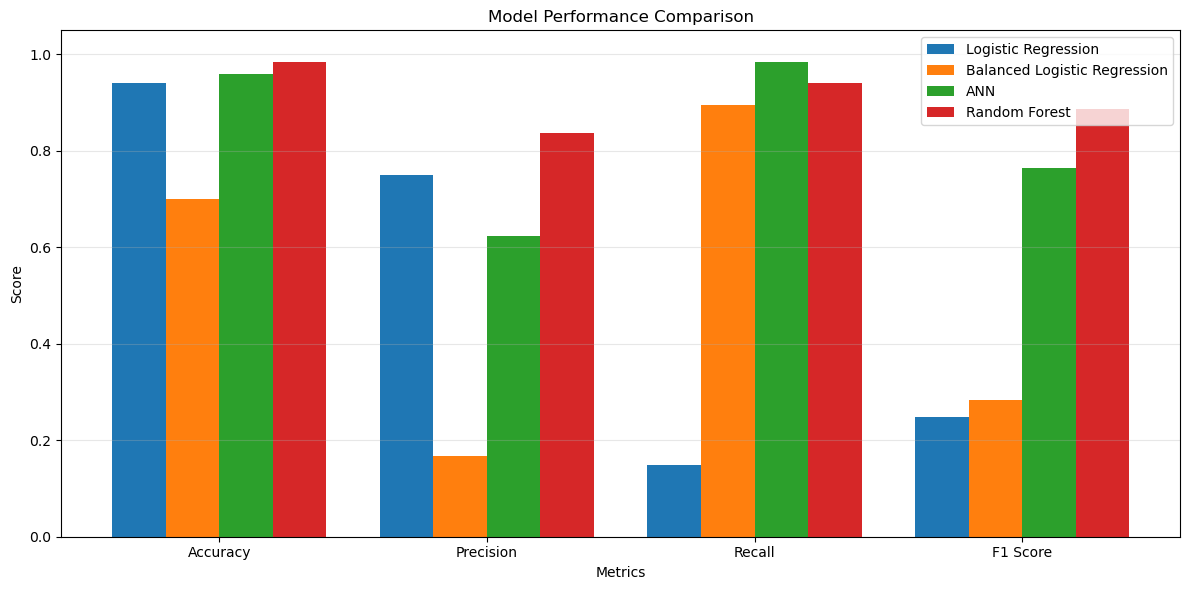

In [59]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

x = np.arange(len(metrics))
width = 0.2

plt.figure(figsize=(12, 6))

for i, (_, row) in enumerate(comparison.iterrows()):
    plt.bar(
        x + (i - 1.5) * width,
        [
            row["Accuracy"],
            row["Precision"],
            row["Recall"],
            row["F1 Score"]
        ],
        width,
        label=row["Model"]
    )

plt.xlabel("Metrics")
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                      Feature  Importance
5                   OUT_BYTES    0.205618
7                    OUT_PKTS    0.163926
4                    IN_BYTES    0.157849
9  FLOW_DURATION_MILLISECONDS    0.124572
1                 L4_DST_PORT    0.115878
6                     IN_PKTS    0.085945
8                   TCP_FLAGS    0.070038
3                    L7_PROTO    0.036989
0                 L4_SRC_PORT    0.021897
2                    PROTOCOL    0.017288


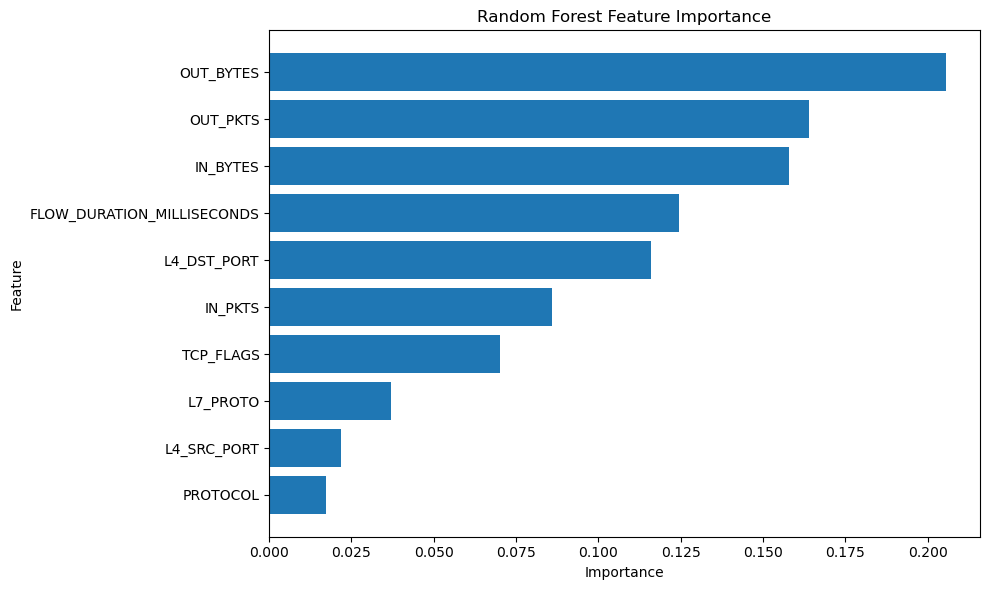

In [63]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Saving all the models

In [68]:
import os
import joblib

model_dir = r"E:\GitHub\Network-Intrusion-Detection-System\models"
os.makedirs(model_dir, exist_ok=True)

# Logistic Regression
joblib.dump(
    lr_model,
    os.path.join(model_dir, "logistic_regression.pkl")
)

# Balanced Logistic Regression
joblib.dump(
    lr_balanced,
    os.path.join(model_dir, "balanced_logistic_regression.pkl")
)

# ANN
ann_model.save(
    os.path.join(model_dir, "ann_model.keras")
)

print("All models saved successfully!")
print("\nSaved models:")
print("- logistic_regression.pkl")
print("- balanced_logistic_regression.pkl")
print("- ann_model.keras")
print("- nids_random_forest.pkl")

All models saved successfully!

Saved models:
- logistic_regression.pkl
- balanced_logistic_regression.pkl
- ann_model.keras
- nids_random_forest.pkl


In [66]:
import os
import joblib

model_dir = r"E:\GitHub\Network-Intrusion-Detection-System\models"

os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(model_dir, "nids_random_forest.pkl")

joblib.dump(rf_model, model_path)

print("Random Forest model saved successfully.")
print("Saved at:", model_path)

Random Forest model saved successfully.
Saved at: E:\GitHub\Network-Intrusion-Detection-System\models\nids_random_forest.pkl


In [69]:
import joblib
import os

model_dir = r"E:\GitHub\Network-Intrusion-Detection-System\models"
os.makedirs(model_dir, exist_ok=True)

scaler_path = os.path.join(model_dir, "standard_scaler.pkl")

joblib.dump(scaler, scaler_path)

print("Scaler saved successfully!")
print("Saved at:", scaler_path)

Scaler saved successfully!
Saved at: E:\GitHub\Network-Intrusion-Detection-System\models\standard_scaler.pkl
